# PC03 — Thiết kế thực nghiệm, lựa chọn thuật toán và số cụm

## Mục tiêu nghiệp vụ
Một mô hình có chỉ số đẹp chưa chắc tạo ra nhóm dễ hiểu hoặc hữu ích. Ngược lại, ép khách vào các nhãn quen thuộc có thể tạo câu chuyện không được dữ liệu hỗ trợ. PC03 cân bằng **cấu trúc thống kê, độ ổn định, quy mô nhóm và khả năng diễn giải**.

Notebook thực sự huấn luyện lại 14 cấu hình K-Means, khảo sát k=2–8 ở hai cách biểu diễn, rồi giữ một số ứng viên. Sau đó kiểm seed và đối chứng Hierarchical trên cùng mẫu. Không dùng nhãn k=3 của bản trước để huấn luyện hoặc đánh giá mô hình mới.

## Đầu vào và đầu ra
Đầu vào là RFM được kiểm chứng, không gồm `customer_id` hay nhãn nghiệp vụ. Đầu ra gồm cấu hình, chỉ số, quy mô cụm, hồ sơ sơ bộ, sample ID, tâm/scaler và một **đề xuất kỹ thuật**. PC04 tiếp tục thẩm định ý nghĩa nhóm, PC05 chốt mức sẵn sàng sử dụng.

Các ví dụ nhỏ dưới đây giúp đọc công thức. Chúng là bài toán minh họa riêng, không là mô hình trên 85.115 khách.


## Bản đồ ký hiệu và nguyên tắc đọc công thức

| Ký hiệu | Ý nghĩa trong notebook |
|---|---|
| c / i | Khách / chỉ số điểm dữ liệu; đọc định nghĩa tại từng công thức |
| o | Một order_id; không phải một dòng sản phẩm |
| E | Tập khách đủ điều kiện RFM delivered |
| T | Mốc31/12/2022 |
| n | Số khách của tập đang phân tích |
| k, Cj | Số cụm và tập khách của cụm j |
| R/F/M | Giá trị thô trên cùng tập đơn đủ điều kiện |
| x, z | Giá trị trước/sau biến đổi theo ngữ cảnh |
| μ, σ | Trung bình/tâm và độ lệch chuẩn, định nghĩa cụ thể cạnh công thức |

Một ký hiệu có thể dùng ở cấp khác trong một công thức khác; mỗi mục đều giải thích phạm vi và mẫu số. Đọc đơn vị, thời gian và trạng thái trước khi so số. Công thức minh họa và kết quả dự án được tách rõ. Các hàm Python giữ tên tiếng Anh để tái sử dụng; nội dung trình bày bằng tiếng Việt.


## Chuẩn bị môi trường và nguồn dữ liệu

Chạy với dữ liệu mô hình đã lưu trong data/model/phan_khuc/v1. Để huấn luyện lại từ PC03, đặt biến môi trường DATATHON_MODEL_RUN thành một tên lượt mới.

In [1]:
from pathlib import Path
import sys,json
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from pathlib import Path
import json
import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next(
    (path for path in (start, *start.parents)
     if (path / "notebook/00_ham_dung_chung.ipynb").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")

support_file = ROOT / "notebook/00_ham_dung_chung.ipynb"
support_doc = json.loads(support_file.read_text(encoding="utf-8"))
loader = "".join(support_doc["cells"][1]["source"])
exec(compile(loader, str(support_file), "exec"), {"SUPPORT_FILE": support_file})
from datathon.runtime import read_reference, reference_path

from datathon.segmentation.study import Study,share_table,concentration,distribution
from datathon.segmentation.rfm_features import rfm
from datathon.segmentation.transformations import feature_matrix
from datathon.segmentation._shared import require,FEATURES,CUTOFF
MODEL_LABEL = os.environ.get("DATATHON_MODEL_RUN", "v1")
study = Study(ROOT, "PC03")
pd.set_option('display.max_columns',20)
print('Phần phân tích:', study.part, '| Lượt mô hình:', MODEL_LABEL)


Phần phân tích: PC03 | Thư mục kết quả: /workspace/scratch/1f9612b45e80/professional/DA_PC/reports/segmentation/professional_v1/PC03


## PC03.1 — Thiết kế thí nghiệm và tiêu chí ra quyết định

**Câu hỏi:** làm sao biết khác biệt kết quả đến từ phép biến đổi hoặc số cụm, thay vì đổi tập khách và cách đánh giá?

Giữ cùng tập E, cùng RFM, seed và n_init; thay cách biểu diễn TN1/TN2 và k. Với mỗi thí nghiệm, fit trên toàn E. Dùng một danh sách 5.000 mã khách lấy không hoàn lại để tính Silhouette cho mọi cấu hình; danh sách được lưu để truy vết.

| Yếu tố | Cố định hay thay đổi? | Mục đích |
|---|---|---|
| Tập khách và công thức | Cố định | So cùng đối tượng và định nghĩa |
| TN1/TN2 | Thay đổi | Xem ảnh hưởng cách đo khoảng cách |
| k=2..8 | Thay đổi | Khảo sát độ chi tiết |
| Seed42, n_init10 | Cố định ở vòng grid | Hạn chế khác biệt do khởi tạo |
| Seed7/21/84 | Thay đổi ở vòng ổn định | Kiểm phân hoạch nhạy khởi tạo không |

Không có nhãn “đúng” của khách nên đây không phải bài phân loại; không báo accuracy hoặc precision/recall. Silhouette/DB/Inertia là bằng chứng nội bộ. Danh sách mẫu dùng chọn mô hình chưa phải holdout độc lập.

**Nguyên tắc nghiệp vụ:** trước tiên loại cách diễn giải không hợp lệ về phạm vi/tiền; sau đó đọc chỉ số, quy mô và hồ sơ. Không chọn mô hình chỉ vì tạo đúng ba tên nhóm mong muốn hoặc một chỉ số cao nhất. Cách chọn tự động trong code là shortlist thăm dò; quyết định sử dụng còn cần PC04/PC05.


In [2]:
design=pd.DataFrame([{'Mục':'Dữ liệu','Quy tắc':'RFM toàn lịch sử delivered, R mốc31/12/2022'}, {'Mục':'TN1','Quy tắc':'RFM gốc → StandardScaler'}, {'Mục':'TN2','Quy tắc':'R gốc, log1p(F,M) → StandardScaler'}, {'Mục':'k','Quy tắc':'2..8'}, {'Mục':'KMeans','Quy tắc':'k-means++, n_init10, seed42, max_iter300'}, {'Mục':'Đánh giá','Quy tắc':'Silhouette cùng5000 khách; DB và Inertia toàn tập'}])
study.table('design','Thiết kế thực nghiệm',design)

Out[2]: 
        Mục                                            Quy tắc
0   Dữ liệu        RFM toàn lịch sử delivered, R mốc31/12/2022
1       TN1                           RFM gốc → StandardScaler
2       TN2                 R gốc, log1p(F,M) → StandardScaler
3         k                                               2..8
4    KMeans           k-means++, n_init10, seed42, max_iter300
5  Đánh giá  Silhouette cùng5000 khách; DB và Inertia toàn tập


,Mục,Quy tắc
0,Dữ liệu,"RFM toàn lịch sử delivered, R mốc31/12/2022"
1,TN1,RFM gốc → StandardScaler
2,TN2,"R gốc, log1p(F,M) → StandardScaler"
3,k,2..8
4,KMeans,"k-means++, n_init10, seed42, max_iter300"
5,Đánh giá,Silhouette cùng5000 khách; DB và Inertia toàn tập


## PC03.2 — K-Means: hàm mục tiêu và các bước thực hiện

**Trực giác:** mỗi khách được biểu diễn bởi vector $x_i=(z_{i,R},z_{i,F},z_{i,M})$ sau biến đổi/chuẩn hóa. Khách gần một tâm hơn được gán vào cụm tâm đó. Tâm cụm là trung bình vector các khách trong cụm.

Với k cụm $C_1,\ldots,C_k$ và tâm $\mu_1,\ldots,\mu_k$, hàm mục tiêu:

$$J=\sum_{j=1}^{k}\sum_{x_i\in C_j}\|x_i-\mu_j\|_2^2.$$

Mỗi vòng gồm:

$$label_i=\arg\min_j\|x_i-\mu_j\|_2^2,$$

$$\mu_j=\frac{1}{|C_j|}\sum_{x_i\in C_j}x_i.$$

| Ký hiệu | Ý nghĩa |
|---|---|
| $x_i$ | Vector RFM đã biến đổi, không gồm mã khách |
| $C_j$ | Tập khách được gán cụm j |
| $\mu_j$ | Tâm trong không gian mô hình, không trực tiếp là tiền/ngày gốc |
| $\|x_i-\mu_j\|_2^2$ | Tổng bình phương chênh từng trục |
| J | Tổng độ phân tán trong cụm, thường gọi Inertia |

**Ví dụ 2 chiều riêng để tính tay:** các điểm(0,0),(0,2),(8,8),(8,10), hai tâm đầu(0,0),(8,8). Sau gán, hai điểm đầu vào cụm1, hai điểm cuối vào cụm2. Tâm mới là(0,1),(8,9); J từ8 xuống4. Đây không phải dữ liệu khách dự án và không chứng minh k=2 phù hợp cho dữ liệu thật.

`k-means++` khởi tạo có ưu tiên khoảng cách để giảm nguy cơ tâm bắt đầu quá gần; không bảo đảm nghiệm tối ưu toàn cục. `n_init=10` thử10 khởi tạo, giữ nghiệm có Inertia nhỏ nhất trong cấu hình; `random_state=42` giúp tái lập. `max_iter=300` là trần số vòng, không có nghĩa luôn chạy đủ300. K-Means có thể đạt nghiệm cục bộ và nhạy với thang đo/điểm cực đoan.

**Liên hệ code:** `workflow.experiments()` chạy thật14 cấu hình. Core thuật toán ở module để tái sử dụng; notebook vẫn trình bày mục tiêu và quyết định trước bảng kết quả.

Tài liệu: [K-Means và các giả định khoảng cách](https://scikit-learn.org/stable/modules/clustering.html#k-means).


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [3]:
# VÍ DỤ GIẢ LẬP 2CHIỀU: một vòng gán điểm rồi cập nhật tâm.
toy_x=np.array([[0.,0.],[0.,2.],[8.,8.],[8.,10.]])
toy_centers=np.array([[0.,0.],[8.,8.]])
toy_dist2=((toy_x[:,None,:]-toy_centers[None,:,:])**2).sum(axis=2)
toy_labels=toy_dist2.argmin(axis=1)
toy_new=np.vstack([toy_x[toy_labels==j].mean(axis=0) for j in range(2)])
toy_J_before=toy_dist2[np.arange(4),toy_labels].sum();toy_J_after=((toy_x-toy_new[toy_labels])**2).sum()
assert toy_J_before==8 and toy_J_after==4
study.table('VD04_kmeans','Ví dụ giả lập — khoảng cách bình phương và nhãn',pd.DataFrame({'Điểm':['A','B','C','D'],'x1':toy_x[:,0],'x2':toy_x[:,1],'d² tâm0':toy_dist2[:,0],'d² tâm1':toy_dist2[:,1],'Nhãn sau gán':toy_labels}))
study.table('VD04_tam','Ví dụ giả lập — tâm sau cập nhật',pd.DataFrame({'Tâm':[0,1],'x1 cũ':toy_centers[:,0],'x2 cũ':toy_centers[:,1],'x1 mới':toy_new[:,0],'x2 mới':toy_new[:,1]}))
study.note(f'Ví dụ2chiều: J từ {toy_J_before:.0f} xuống {toy_J_after:.0f}. Bài toán thật dùng3trục RFM đã chuẩn hóa; không dùng bốn điểm này làm khách thật.')

,Điểm,x1,x2,d² tâm0,d² tâm1,Nhãn sau gán
0,A,0.0,0.0,0.0,128.0,0
1,B,0.0,2.0,4.0,100.0,0
2,C,8.0,8.0,128.0,0.0,1
3,D,8.0,10.0,164.0,4.0,1


,Tâm,x1 cũ,x2 cũ,x1 mới,x2 mới
0,0,0.0,0.0,0.0,1.0
1,1,8.0,8.0,8.0,9.0


Ví dụ2chiều: J từ 8 xuống 4. Bài toán thật dùng3trục RFM đã chuẩn hóa; không dùng bốn điểm này làm khách thật.

In [4]:
from types import SimpleNamespace
from datathon.segmentation.workflow import Workflow

model_dir = study.model_root / MODEL_LABEL
train_model = not model_dir.exists()
if train_model:
    workflow = Workflow(ROOT, label=MODEL_LABEL)
    workflow.audit()
    workflow.prepare()
    workflow.behavior()
    require(workflow.features.customer_id.tolist() == study.f.customer_id.tolist(), "Khác tập khách RFM")
    grid = workflow.experiments()
    result_source = "lượt tính mới"
else:
    saved_model = study.use_model(MODEL_LABEL)
    selected = saved_model["selected"]
    grid = pd.read_csv(model_dir / "experiment_grid.csv")
    workflow = SimpleNamespace(
        out=model_dir,
        grid=grid,
        key=(selected["variant"], int(selected["k"])),
        shortlist=pd.read_csv(model_dir / "shortlist.csv"),
        profiles=pd.read_csv(model_dir / "cluster_profiles.csv"),
    )
    result_source = "lượt đã lưu"
study.table("experiment_grid", f"Kết quả 14 cấu hình — {result_source}", grid)


TN1, k=2: silhouette=0.5171; min_share=22.25%
TN1, k=3: silhouette=0.4589; min_share=12.07%
TN1, k=4: silhouette=0.4416; min_share=4.42%
TN1, k=5: silhouette=0.4007; min_share=3.99%
TN1, k=6: silhouette=0.4008; min_share=1.96%
TN1, k=7: silhouette=0.3911; min_share=1.09%
TN1, k=8: silhouette=0.3970; min_share=0.94%
TN2, k=2: silhouette=0.4687; min_share=49.85%
TN2, k=3: silhouette=0.3852; min_share=29.65%
TN2, k=4: silhouette=0.3330; min_share=21.05%
TN2, k=5: silhouette=0.3410; min_share=15.11%
TN2, k=6: silhouette=0.3296; min_share=10.65%
TN2, k=7: silhouette=0.3199; min_share=9.04%
TN2, k=8: silhouette=0.3181; min_share=7.51%
Out[4]: 
   variant  k  silhouette_sample  davies_bouldin_full        inertia  \
0      TN1  2           0.517096             0.783078  130752.023217   
1      TN1  3           0.458908             0.743269   75607.122860   
2      TN1  4           0.441575             0.748110   53509.804174   
3      TN1  5           0.400697             0.784373   42122.2588

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


,Thí nghiệm,Số cụm,Silhouette mẫu,Davies–Bouldin toàn tập,Inertia,Tỷ trọng cụm nhỏ nhất,Tỷ trọng cụm lớn nhất,seconds
0,TN1,2,0.517096,0.783078,130752.023217,0.222511,0.777489,0.326729
1,TN1,3,0.458908,0.743269,75607.122860,0.120719,0.473971,0.284777
2,TN1,4,0.441575,0.748110,53509.804174,0.044234,0.402867,0.314349
3,TN1,5,0.400697,0.784373,42122.258897,0.039911,0.301944,0.319635
4,TN1,6,0.400804,0.780048,33170.523489,0.019597,0.281090,0.416213
5,TN1,7,0.391050,0.830567,28932.962652,0.010903,0.279469,0.372017
6,TN1,8,0.397023,0.836701,25818.567363,0.009387,0.255313,0.395127
7,TN2,2,0.468739,0.787364,109471.395139,0.498479,0.501521,0.218766
8,TN2,3,0.385208,0.939087,75069.760434,0.296516,0.377818,0.253482
9,TN2,4,0.333022,1.038917,61238.684971,0.210468,0.308442,0.352608


## PC03.3 — Inertia, Silhouette và Davies–Bouldin: công thức và cách đọc

### a. Inertia và Elbow
Inertia chính là J ở mục trước, không đơn vị sau chuẩn hóa. Thêm cụm thường làm J giảm vì có thêm tâm để mô tả dữ liệu. Vì vậy không chọn k có J nhỏ nhất một cách máy móc. Elbow tìm vùng mức giảm bắt đầu chậm lại; có thể không có “khuỷu” rõ, và không so Inertia TN1/TN2 như cùng hình học.

### b. Silhouette: một khách gần nhóm mình hơn nhóm khác bao nhiêu?
Với khách i trong cụm $C(i)$:

$$a(i)=\frac{1}{|C(i)|-1}\sum_{h\in C(i),h\ne i}d(i,h).$$

$a(i)$ là khoảng cách trung bình đến các khách **khác** cùng cụm. Với mỗi cụm khác, tính khoảng cách trung bình từ i đến cụm đó, lấy giá trị nhỏ nhất:

$$b(i)=\min_{G\ne C(i)}\frac{1}{|G|}\sum_{h\in G}d(i,h).$$

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))},\qquad S=\frac{1}{m}\sum_{i=1}^{m}s(i).$$

m là số khách được đánh giá. S gần1 là phân tách thuận lợi; gần0 là gần ranh giới; âm cho thấy khách gần cụm khác hơn theo khoảng cách đang dùng. Cụm đơn phần tử được thư viện quy ước s=0; chỉ số tổng chỉ xác định khi số cụm từ2 đến m−1.

**Ví dụ:** a=2,b=5 thì s=0,6. Đây không phải “60% dự đoán đúng”. Trong dự án, S dùng cùng mẫu5000 để giảm chi phí khoảng cách; khoảng cách nội bộ được tính trong chính mẫu, không phải đầy đủ toàn tập.

### c. Davies–Bouldin: độ phân tán so với khoảng cách tâm
Với cụm j có tâm $\mu_j$, dùng khoảng cách Euclid không bình phương:

$$S_j=\frac{1}{|C_j|}\sum_{x_i\in C_j}\|x_i-\mu_j\|_2,$$

$$D_{j\ell}=\frac{S_j+S_\ell}{\|\mu_j-\mu_\ell\|_2},$$

$$DB=\frac{1}{k}\sum_{j=1}^{k}\max_{\ell\ne j}D_{j\ell}.$$

Tử số thể hiện hai cụm rộng; mẫu số thể hiện hai tâm xa. DB thấp thuận lợi. Với hai cụm có độ phân tán1 và1, khoảng cách tâm5 thì DB=0,4 trong ví dụ lý tưởng đó. DB không bị chặn ở1 và không phải tỷ lệ lỗi.

**Quy tắc so sánh:** trong dự án DB tính toàn tập, Silhouette tính mẫu. Hai chỉ số khác định nghĩa và phạm vi đánh giá, nên có thể ưu tiên k khác nhau. Cần đọc bảng và hồ sơ, không đổi trọng số sau khi thấy kết quả chỉ để hợp k mong muốn.

Nguồn: [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html), [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [5]:
# VÍ DỤ GIẢ LẬP: đối chiếu công thức Silhouette/DB với thư viện.
from sklearn.metrics import silhouette_samples,davies_bouldin_score
toy_x=np.array([[0.],[2.],[10.],[12.]]);toy_labels=np.array([0,0,1,1]);toy_d=np.abs(toy_x-toy_x.T);toy_rows=[]
for i in range(4):
 same=(toy_labels==toy_labels[i]);same[i]=False;toy_a=toy_d[i,same].mean();toy_b=min(toy_d[i,toy_labels==g].mean() for g in np.unique(toy_labels) if g!=toy_labels[i]);toy_s=(toy_b-toy_a)/max(toy_a,toy_b)
 toy_rows.append({'Điểm':float(toy_x[i,0]),'Cụm':int(toy_labels[i]),'a(i)':toy_a,'b(i)':toy_b,'s(i) tính tay':toy_s})
toy_t=pd.DataFrame(toy_rows);assert np.allclose(toy_t['s(i) tính tay'],silhouette_samples(toy_x,toy_labels))
toy_centers=np.array([toy_x[toy_labels==g].mean() for g in [0,1]]);toy_spread=np.array([np.abs(toy_x[toy_labels==g].ravel()-toy_centers[g]).mean() for g in [0,1]])
toy_db=toy_spread.sum()/abs(toy_centers[0]-toy_centers[1]);assert np.isclose(toy_db,davies_bouldin_score(toy_x,toy_labels))
study.table('VD05_silhouette','Ví dụ giả lập — s(i) tính tay khớp thư viện',toy_t)
study.note(f'Ví dụ: Silhouette trung bình={toy_t["s(i) tính tay"].mean():.6f}; S0=S1=1, khoảng tâm10 nên DB={toy_db:.3f}. Không gọi đây là phần trăm dự đoán đúng.')

,Điểm,Cụm,a(i),b(i),s(i) tính tay
0,0.0,0,2.0,11.0,0.818182
1,2.0,0,2.0,9.0,0.777778
2,10.0,1,2.0,9.0,0.777778
3,12.0,1,2.0,11.0,0.818182


Ví dụ: Silhouette trung bình=0.797980; S0=S1=1, khoảng tâm10 nên DB=0.200. Không gọi đây là phần trăm dự đoán đúng.

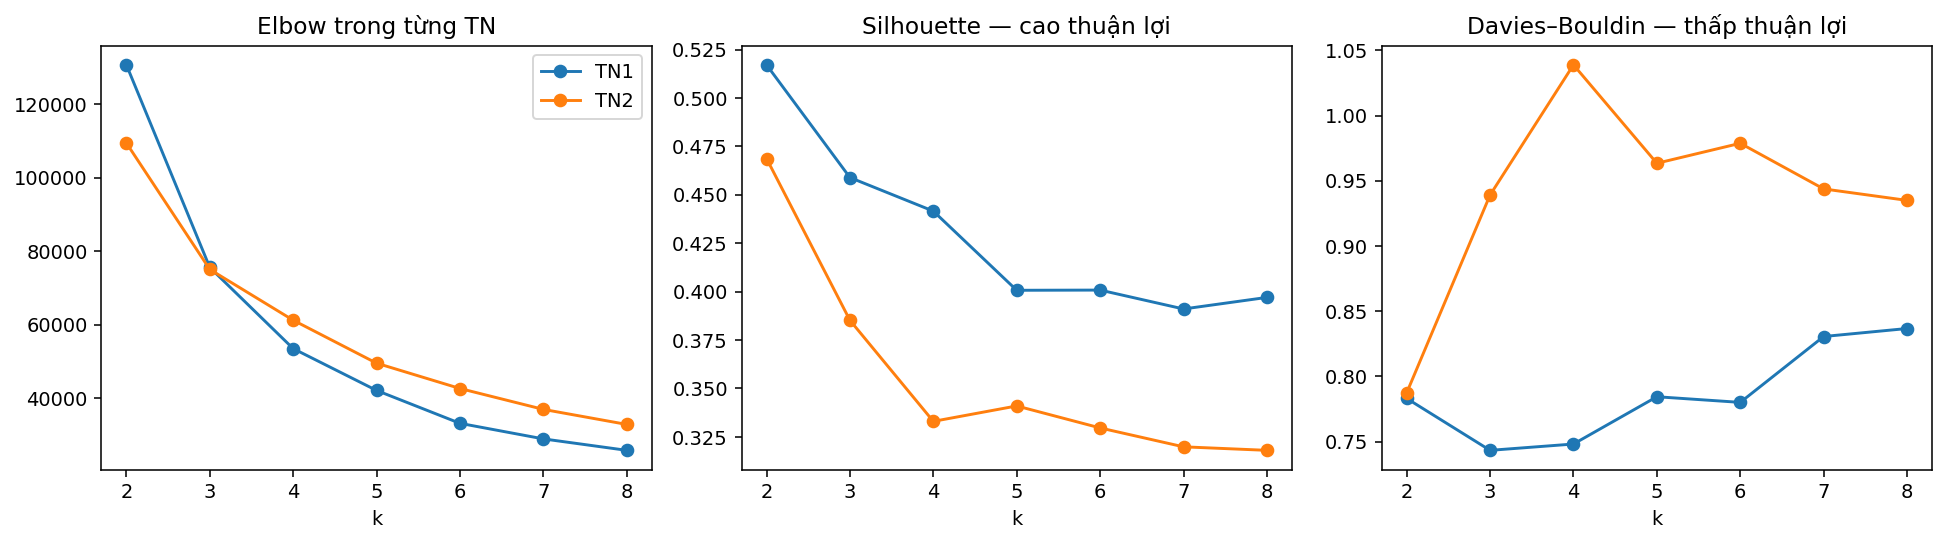

Silhouette cao nhất: TN1, k=2 (0.5171); DB thấp nhất: TN1, k=3 (0.7433). Nếu khác nhau, cần đọc quy mô và hồ sơ, không kết luận một chỉ số quyết định tất cả.

In [6]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
for name,g in grid.groupby('variant'):
 for ax,col,title in zip(axes,['inertia','silhouette_sample','davies_bouldin_full'],['Elbow trong từng TN','Silhouette — cao thuận lợi','Davies–Bouldin — thấp thuận lợi']):ax.plot(g.k,g[col],marker='o',label=name);ax.set(title=title,xlabel='k')
axes[0].legend();study.fig('model_metrics','Ba góc nhìn lựa chọn mô hình',fig)
best_s=grid.loc[grid.silhouette_sample.idxmax()];best_db=grid.loc[grid.davies_bouldin_full.idxmin()]
study.note(f'Silhouette cao nhất: {best_s.variant}, k={int(best_s.k)} ({best_s.silhouette_sample:.4f}); DB thấp nhất: {best_db.variant}, k={int(best_db.k)} ({best_db.davies_bouldin_full:.4f}). Nếu khác nhau, cần đọc quy mô và hồ sơ, không kết luận một chỉ số quyết định tất cả.')

## PC03.4 — Quy mô cụm, shortlist và đánh đổi k=2/3/4

**Câu hỏi:** mô hình có tạo một nhóm quá nhỏ hoặc một nhóm chiếm gần hết không?

Với nhóm j:

$$Share_j=\frac{|C_j|}{n}.$$

Ngưỡng cụm nhỏ nhất ≥1% là quy tắc thăm dò của nghiên cứu, không luật kinh doanh. Một cụm nhỏ có thể quan trọng; nếu bị loại cần ghi rõ quy tắc chứ không gọi nó là nhóm vô nghĩa.

Để tạo danh sách ngắn, xếp hạng Silhouette giảm dần và DB tăng dần trong các cấu hình đủ quy mô:

$$RankSum=Rank_{S\downarrow}+Rank_{DB\uparrow}.$$

Giá trị nhỏ được ưu tiên; hòa ưu tiên k nhỏ hơn. Đây là cách tổng hợp hai thứ hạng, không xác suất mô hình tốt và không chứng minh hai chỉ số có giá trị kinh doanh bằng nhau. Code lưu mọi cấu hình và hồ sơ để người đọc phản biện shortlist.

**Đọc ứng viên:** k=2 có thể đủ khi chỉ cần hai mức giá trị rộng; k=3 có thể phân biệt thêm mức hoạt động trung gian; k=4 có thể tách đuôi nhưng tăng số nhóm cần quản lý. Những mô tả này phải được kiểm bằng hồ sơ và bảng chéo thực tế ở PC04, không coi là kết quả có trước.

**Quyết định:** chưa đặt tên VIP/churn trong bước chọn k. Giữ ít nhất các đối thủ có cơ sở để minh bạch đánh đổi, thay vì chỉ trình bày một mô hình đã chọn.


In [7]:
study.table('cluster_balance','Quy mô cụm theo cấu hình',grid[['variant','k','min_cluster_share','max_cluster_share']])
study.table('shortlist','Ba ứng viên kỹ thuật',workflow.shortlist)
profiles=pd.read_csv(workflow.out/'candidate_profiles.csv')
study.table('candidate_k234','Hồ sơ k2/3/4 của TN1',profiles[(profiles.variant=='TN1') & profiles.k.isin([2,3,4])])
study.note('Hai cụm có thể chỉ tách mức giá trị; ba/bốn cụm có thể bổ sung hoạt động hoặc chia nhỏ đuôi. Phải kiểm hồ sơ thực tế, không mặc định nhiều cụm hơn hữu ích hơn.')

,Thí nghiệm,Số cụm,Tỷ trọng cụm nhỏ nhất,Tỷ trọng cụm lớn nhất
0,TN1,2,0.222511,0.777489
1,TN1,3,0.120719,0.473971
2,TN1,4,0.044234,0.402867
3,TN1,5,0.039911,0.301944
4,TN1,6,0.019597,0.281090
5,TN1,7,0.010903,0.279469
6,TN1,8,0.009387,0.255313
7,TN2,2,0.498479,0.501521
8,TN2,3,0.296516,0.377818
9,TN2,4,0.210468,0.308442


,Thí nghiệm,Số cụm,Silhouette mẫu,Davies–Bouldin toàn tập,Inertia,Tỷ trọng cụm nhỏ nhất,Tỷ trọng cụm lớn nhất,seconds,Tổng hạng
1,TN1,3,0.458908,0.743269,75607.122860,0.120719,0.473971,0.284777,4.0
0,TN1,2,0.517096,0.783078,130752.023217,0.222511,0.777489,0.326729,5.0
2,TN1,4,0.441575,0.748110,53509.804174,0.044234,0.402867,0.314349,6.0


,Thí nghiệm,Số cụm,Nhóm,Số khách,R trung vị,F trung vị,M trung vị
0,TN1,2,0,18939,271.0,14.0,354134.310
1,TN1,2,1,66176,1592.0,2.0,52773.190
2,TN1,3,0,40342,598.0,5.0,124473.995
3,TN1,3,1,10275,244.0,19.0,477244.080
4,TN1,3,2,34498,2307.0,1.0,29651.965
5,TN1,4,0,34290,747.0,4.0,88140.730
6,TN1,4,1,31120,2390.0,1.0,28113.800
7,TN1,4,2,3765,191.0,27.0,674514.020
8,TN1,4,3,15940,328.0,12.0,312238.310


Hai cụm có thể chỉ tách mức giá trị; ba/bốn cụm có thể bổ sung hoạt động hoặc chia nhỏ đuôi. Phải kiểm hồ sơ thực tế, không mặc định nhiều cụm hơn hữu ích hơn.

## PC03.5 — Ổn định khởi tạo và Adjusted Rand Index

**Câu hỏi:** cùng dữ liệu nhưng đổi khởi tạo có tạo nhóm rất khác không?

Hai lần chạy có thể hoán đổi số nhãn dù gom khách giống hệt. Vì vậy không đếm trực tiếp `label_a != label_b` để đánh giá hai mô hình refit. ARI xét quan hệ từng cặp khách: cùng cụm hay khác cụm trong hai phân hoạch, có hiệu chỉnh theo sự trùng hợp ngẫu nhiên.

Với bảng chéo $n_{rs}$ giữa phân hoạch A/B, tổng hàng $a_r$, tổng cột $b_s$, định nghĩa $P(u)=u(u-1)/2$ là số cặp không thứ tự:

$$I=\sum_{r,s}P(n_{rs}),\quad A=\sum_r P(a_r),\quad B=\sum_s P(b_s),\quad N=P(n).$$

$$E_I=\frac{AB}{N},\qquad ARI=\frac{I-E_I}{(A+B)/2-E_I}.$$

A và B là tổng số cặp cùng cụm trong hai phân hoạch tương ứng; P(u) là hàm đếm cặp và N là số cặp khách toàn tập. Khi mẫu số suy biến, dùng quy ước thư viện thay vì tự chia0.

ARI=1 nghĩa là hai phân hoạch giống nhau tới hoán đổi nhãn; gần0 là mức tương đồng kỳ vọng theo mô hình ngẫu nhiên hiệu chỉnh; có thể âm. Không phải phần trăm khách được dự đoán đúng.

**Ví dụ:** A=[0,0,1,1], B=[1,1,0,0] có ARI=1 dù mọi số nhãn khác nhau. Đổi seed7/21/84 trên cùng khách kiểm một loại độ ổn định. Ngưỡng mean ARI≥0,90 chỉ là cổng thăm dò; ổn định seed chưa bảo đảm bền qua thời gian, nguồn hay cách chọn đặc trưng.

Nguồn: [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [8]:
# VÍ DỤ GIẢ LẬP: nhãn hoán đổi và bảng chéo ARI.
from sklearn.metrics import adjusted_rand_score
toy_a=np.array([0,0,1,1]);toy_cases={'Hoán đổi số nhãn':np.array([1,1,0,0]),'Chia chéo':np.array([0,1,0,1])};toy_rows=[]
for name,toy_b in toy_cases.items():
 toy_ct=pd.crosstab(toy_a,toy_b).to_numpy();toy_pair=lambda v:np.asarray(v)*(np.asarray(v)-1)/2
 toy_I=toy_pair(toy_ct).sum();toy_A=toy_pair(toy_ct.sum(axis=1)).sum();toy_B=toy_pair(toy_ct.sum(axis=0)).sum();toy_N=toy_pair(len(toy_a));toy_E=toy_A*toy_B/toy_N;toy_ari=(toy_I-toy_E)/((toy_A+toy_B)/2-toy_E)
 assert np.isclose(toy_ari,adjusted_rand_score(toy_a,toy_b))
 toy_rows.append({'Trường hợp':name,'I':toy_I,'A':toy_A,'B':toy_B,'E(I)':toy_E,'ARI tính tay':toy_ari,'Tỷ lệ số nhãn khác':(toy_a!=toy_b).mean()})
study.table('VD06_ARI','Ví dụ giả lập — ARI không phụ thuộc tên nhãn',pd.DataFrame(toy_rows))

Out[8]: 
         Trường hợp    I    A    B      E(I)  ARI tính tay  Tỷ lệ số nhãn khác
0  Hoán đổi số nhãn  2.0  2.0  2.0  0.666667           1.0                 1.0
1         Chia chéo  0.0  2.0  2.0  0.666667          -0.5                 0.5


,Trường hợp,I,A,B,E(I),ARI tính tay,Tỷ lệ số nhãn khác
0,Hoán đổi số nhãn,2.0,2.0,2.0,0.666667,1.0,1.0
1,Chia chéo,0.0,2.0,2.0,0.666667,-0.5,0.5


In [9]:
stable = workflow.stability() if train_model else pd.read_csv(workflow.out / "seed_stability.csv");study.table('seed_stability','Ổn định các ứng viên',stable)
chosen=workflow.key
study.note(f'Đề xuất kỹ thuật sau kiểm ổn định: {chosen[0]}, k={chosen[1]}. Đọc tiếp khả năng phân biệt nhóm ở PC04; seed ổn định chưa chứng minh bền qua thời gian.')

,Thí nghiệm,Số cụm,Seed,ARI
0,TN1,3,7,0.996876
1,TN1,3,21,0.995662
2,TN1,3,84,0.997905
3,TN1,2,7,1.000000
4,TN1,2,21,1.000000
5,TN1,2,84,0.990348
6,TN1,4,7,0.987177
7,TN1,4,21,0.987187
8,TN1,4,84,0.987177


Đề xuất kỹ thuật sau kiểm ổn định: TN1, k=3. Đọc tiếp khả năng phân biệt nhóm ở PC04; seed ổn định chưa chứng minh bền qua thời gian.

## PC03.6 — Hierarchical Ward và thiết kế đối chứng công bằng

**Câu hỏi:** cấu trúc nhóm có chỉ là hệ quả của riêng K-Means không?

Agglomerative Hierarchical bắt đầu từ mỗi điểm là một cụm, rồi gộp dần. Với Ward, chọn cặp gộp có mức tăng tổng bình phương trong cụm nhỏ nhất. Với hai cụm A/B:

$$\Delta(A,B)=\frac{|A||B|}{|A|+|B|}\|\mu_A-\mu_B\|_2^2.$$

$|A|,|B|$ là số khách, $\mu_A,\mu_B$ là tâm trong không gian biến đổi. Ward dùng Euclid; không thay khoảng cách tùy ý rồi giữ cùng ý nghĩa công thức.

**Ví dụ:** hai cụm đơn điểm cách nhau2 có chi phí tăng $1\times1/(1+1)\times2^2=2$. Cặp gần có thể được gộp trước, nhưng kích thước cụm cũng ảnh hưởng chi phí.

Để giảm chi phí, cả K-Means và Ward đều fit trên **cùng mẫu3500 khách**, dùng cùng phép biến đổi đã xác định. Không lấy kết quả Ward fit mẫu để tuyên bố đã phân cấp toàn bộ khách; cũng không so chỉ số fit mẫu với fit toàn tập như cùng điều kiện.

Hai thuật toán tối ưu theo quy trình khác nhau nên ARI thấp chưa chứng minh thuật toán sai. K-Means không tạo cây lồng nhau khi thay k. Hierarchical giúp đối chứng cấu trúc, chưa tự quyết định mô hình chính. DBSCAN chưa được triển khai trong baseline hiện tại; nếu bổ sung phải báo noise và phạm vi tính chỉ số.

Nguồn: [Tổng quan phân cụm và Ward](https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering).

**Phân biệt đại lượng:** Delta ở đây là mức tăng tổng bình phương trong cụm, không tự đồng nhất với mọi quy ước chiều cao dendrogram mà thư viện có thể xuất.


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [10]:
# VÍ DỤ GIẢ LẬP: chi phí gộp Ward phụ thuộc kích thước và khoảng tâm.
toy_ward=pd.DataFrame({'|A|':[1,1,10],'|B|':[1,10,10],'Khoảng tâm':[2.,2.,2.]})
toy_ward['Delta Ward']=toy_ward['|A|']*toy_ward['|B|']/(toy_ward['|A|']+toy_ward['|B|'])*toy_ward['Khoảng tâm']**2
assert toy_ward.iloc[0]['Delta Ward']==2
study.table('VD07_ward','Ví dụ giả lập — cùng khoảng tâm, chi phí gộp khác',toy_ward)

Out[10]: 
   |A|  |B|  Khoảng tâm  Delta Ward
0    1    1         2.0    2.000000
1    1   10         2.0    3.636364
2   10   10         2.0   20.000000


,|A|,|B|,Khoảng tâm,Delta Ward
0,1,1,2.0,2.000000
1,1,10,2.0,3.636364
2,10,10,2.0,20.000000


In [11]:
hier = workflow.hierarchy() if train_model else pd.read_csv(workflow.out / "hierarchical_comparison.csv");study.table('hierarchical_comparison','Đối chứng công bằng trên mẫu',hier)
study.table('hierarchy_ari','Mức đồng thuận hai thuật toán theo k',pd.DataFrame([{'k':int(k),'ARI hai thuật toán':v} for k,v in json.loads((workflow.out/'hierarchy_agreement.json').read_text()).items()]))
study.note('Đồng thuận thấp chưa chứng minh thuật toán sai: tiêu chí gom cụm khác nhau. Chỉ số nội bộ và hồ sơ phải được đọc cùng nhau; DBSCAN chưa triển khai baseline.')

,algorithm,Số cụm,fit_customers,silhouette,davies_bouldin
0,KMeans_sample,2,3500,0.512336,0.787446
1,Hierarchical_Ward_sample,2,3500,0.532819,0.741094
2,KMeans_sample,3,3500,0.457858,0.735586
3,Hierarchical_Ward_sample,3,3500,0.394450,0.797530
4,KMeans_sample,4,3500,0.447029,0.729052
5,Hierarchical_Ward_sample,4,3500,0.400933,0.751120


,Số cụm,ARI hai thuật toán
0,2,0.752306
1,3,0.503250
2,4,0.474515


Đồng thuận thấp chưa chứng minh thuật toán sai: tiêu chí gom cụm khác nhau. Chỉ số nội bộ và hồ sơ phải được đọc cùng nhau; DBSCAN chưa triển khai baseline.

## PC03.7 — Lưu mô hình, nhãn và bằng chứng tái lập

**Câu hỏi:** người khác có thể giải thích một nhãn và tái lập từ đầu vào nào?

Một nhãn chỉ có ý nghĩa cùng cấu hình: nguồn/hash, tập khách, thứ tự đặc trưng, phép biến đổi, scaler, tâm, seed và ánh xạ số nhóm. Nếu dùng scaler mới hoặc đổi thứ tự R/F/M khi dự đoán, cùng một khách có thể nhận nhãn khác mà không phải hành vi đổi.

Với mô hình cố định, quy tắc gán khách mới có đủ đặc trưng là:

$$g(x)=\arg\min_j\|Transform(x)-\mu_j\|_2^2.$$

Transform ở đây gồm đúng phép log của TN và scaler đã fit, không tự fit lại trên khách mới. Trong nghiên cứu này chỉ xuất nhãn cho snapshot, chưa xây dịch vụ gán nhóm vận hành hoặc kiểm drift.

Bước dưới xuất nhãn, hồ sơ gốc, mẫu đánh giá, các kịch bản độ nhạy và manifest; chỉ đánh dấu completed sau các kiểm tra nguồn/tổng hợp. PC04 tiếp tục đọc phân bố và ý nghĩa nghiệp vụ; một trạng thái completed kỹ thuật không thay thế chấp nhận nghiệp vụ.

**Bàn giao:** kết quả đề xuất và đối thủ phải cùng tồn tại. Những kiểm tra giữ nguyên hash bảo vệ dữ liệu, còn hiệu quả của hành động chăm sóc cần thiết kế đánh giá khác.


In [12]:
if train_model:
    workflow.sensitivity()
    workflow.profile()
    workflow.finish()
model_manifest = study.use_model(MODEL_LABEL)
study.table('selected_profile','Hồ sơ phương án đề xuất',workflow.profiles.reset_index(drop=True) if not train_model else workflow.profiles.reset_index())
study.note('PC04 sẽ so sâu k2/3/4 và hồ sơ nhóm. Mô hình này là đề xuất cho mô tả tập delivered, chưa là quyết định nhắm khách hoặc kết luận churn/VIP.')

,Nhóm,Số khách,R trung vị,F trung vị,M trung vị,Tổng Net,TB tỷ trọng cancelled/khách,TB tỷ trọng returned/khách,TB tỷ trọng có returns/khách,TB tỷ trọng thiếu shipment/khách,Số SP khác nhau trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,34498,2307.0,1.0,29651.965,1.435208e+09,0.061616,0.036944,0.036891,0.000000,2.0,0.405310,0.114650
1,1,40342,598.0,5.0,124473.995,5.614874e+09,0.075082,0.045350,0.045252,0.001875,6.0,0.473971,0.448538
2,2,10275,244.0,19.0,477244.080,5.468093e+09,0.082397,0.050480,0.050340,0.000975,20.0,0.120719,0.436812


PC04 sẽ so sâu k2/3/4 và hồ sơ nhóm. Mô hình này là đề xuất cho mô tả tập delivered, chưa là quyết định nhắm khách hoặc kết luận churn/VIP.

## Tổng kết nghiệp vụ và điều kiện bàn giao

Các đoạn dưới được sinh từ kết quả thật của phần phân tích, giữ riêng quan sát và giả thuyết.

In [13]:
study.note("### Kết luận thực nghiệm và điều cần thẩm định nghiệp vụ")
t=workflow.grid;chosen=t[(t.variant==workflow.key[0]) & (t.k==workflow.key[1])].iloc[0]
study.note(f'Đề xuất kỹ thuật là {workflow.key[0]}, k={workflow.key[1]}, Silhouette={chosen.silhouette_sample:.4f}, DB={chosen.davies_bouldin_full:.4f}. Đây là cấu hình đã qua quy tắc shortlist/seed, không phải chiến thắng trên mọi tiêu chí. PC04 cần chứng minh phần chia thêm có hồ sơ khác và có câu hỏi sử dụng; PC05 công bố giới hạn/độ nhạy trước bàn giao.')

### Kết luận thực nghiệm và điều cần thẩm định nghiệp vụ

Đề xuất kỹ thuật là TN1, k=3, Silhouette=0.4589, DB=0.7433. Đây là cấu hình đã qua quy tắc shortlist/seed, không phải chiến thắng trên mọi tiêu chí. PC04 cần chứng minh phần chia thêm có hồ sơ khác và có câu hỏi sử dụng; PC05 công bố giới hạn/độ nhạy trước bàn giao.

## Kiểm chứng và lưu sản phẩm phân tích

Đối chiếu hash nguồn, lưu bảng/hình và manifest. Công thức, ví dụ, kết quả và diễn giải đều nằm trong notebook; báo cáo HTML được xuất từ chính nội dung này.

In [14]:
part_manifest=study.finish()

Hoàn thành: {'part': 'PC03', 'state': 'completed', 'baseline': 'v1', 'model_run': 'professional_model_v1', 'tables': 14, 'figures': 1, 'commentary_blocks': 9, 'raw_unchanged': True, 'baseline_manifest_sha256': '95948f0feb349f3091a85baa3a31a557ae652fa403e35d1be425a915294c3fef'}


## Tài liệu phương pháp và phạm vi tham khảo

- [scikit-learn: K-Means và tổng quan phân cụm](https://scikit-learn.org/stable/modules/clustering.html#k-means).
- [StandardScaler: công thức và quy ước phương sai](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).
- [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).

Các nguồn trên giải thích phương pháp chung; không xác nhận ngữ nghĩa status/payment/delivery_date của bộ dữ liệu. Những định nghĩa nghiệp vụ dự án kế thừa hợp đồng GD2 và quyết định phạm vi đã công bố. Tên phiên bản thư viện chạy thực tế được lưu trong manifest, không suy từ phiên bản trang tài liệu hiện hành.
